# Scipy

SciPy est une librairie qui est complémentaire à NumPy et qui implémente des algorithmes pour résoudre des problèmes numériques.

## Fonctions spéciales

SciPy implémente des fonctions qui ne sont pas dans NumPy comme les fonctions de Bessel, d'Airy, la fonction d'erreur, ... Elles se trouvent dans le module [```scipy.special```](https://docs.scipy.org/doc/scipy/reference/special.html).

Tracer la fonction d'erreur (la primitive de $\frac{2}{\sqrt{\pi}}e^{-x^2}$) entre -5 et 5.

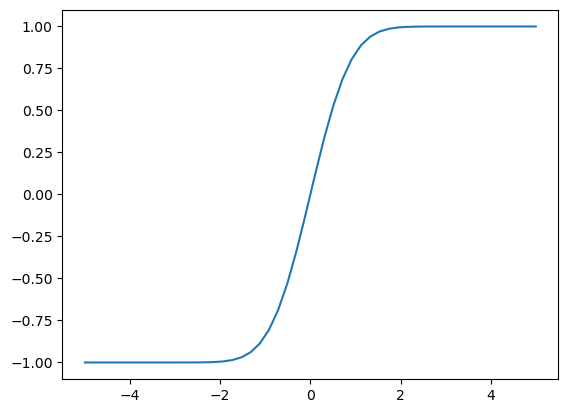

In [1]:
from scipy.special import erf
from matplotlib.pyplot import figure
import numpy as np

fig = figure()
ax = fig.subplots(1, 1)

x = np.linspace(-5, 5)
ax.plot(x, erf(x))


## Intégrales numérique

La fonciton ```quad``` de SciPy permet de calculer une intégrale numérique. 

* Calculer numériquement $\int_0^1 cos(x^3/3)$
* Calculer numériquement $\int_0^\infty \frac{2}{\sqrt{\pi}}e^{-x^2}$ (on utilisera ```np.inf```)

L'algorithme permet de trouver automatiquement les points où il faut évaluer la fonction. Il peut aussi calculer des intégrales avec une borne infinie. Lorsque l'on connaît la fonction, il ne faut donc surtout par utiliser un tableau de point !!

* Combien de point faut-il à scipy pour calculer $\int_0^\infty \frac{2}{\sqrt{\pi}}e^{-x^2}$ ? (pour cela on utilisera une variable globale ou un object que l'on modifiera pour enregistrer chaque appel de la fonction)

In [18]:
import numpy as np
from scipy.integrate import quad

val, _ = quad(lambda x:np.cos(x**3/3), 0, 1)
print(val)

0.9921029614250154


In [21]:
val, _ = quad(lambda x:np.exp(-x**2)*2/np.sqrt(np.pi), 0, np.inf)
print(val)

1.0


In [28]:
list_appel = []
def fonc_to_integrate(x):
    list_appel.append(x)
    return np.exp(-x**2)*2/np.sqrt(np.pi)

val, _ = quad(fonc_to_integrate, 0, np.inf)
print(val)
print(len(list_appel))

1.0
135


## Optimisation

Nous avons déjà vu l'ajustement d'une courbe. Voici d'autres exemples d'optimisation

### Zéro d'une fonction

- En utilisant la fonction ```root_scalar```, calculer la plus petite solution non nulle de l'équation $\tan(x) = x$ (on pourra commencer par visualiser graphiquement l'équation puis afficher le résultat sur le graphique par un point)


(-10.0, 10.0)

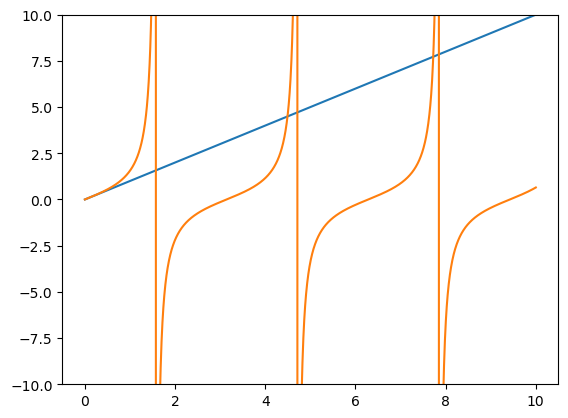

In [29]:
x = np.linspace(0, 10, 2001)
plt.plot(x, x)
plt.plot(x, np.tan(x))
plt.ylim(-10, 10)


In [30]:
from scipy.optimize import root_scalar

def f(x):
    return np.tan(x) - x

res = root_scalar(f, bracket=[4, 4.7], method='brentq')
res


      converged: True
           flag: converged
 function_calls: 12
     iterations: 11
           root: 4.493409457909064
         method: brentq

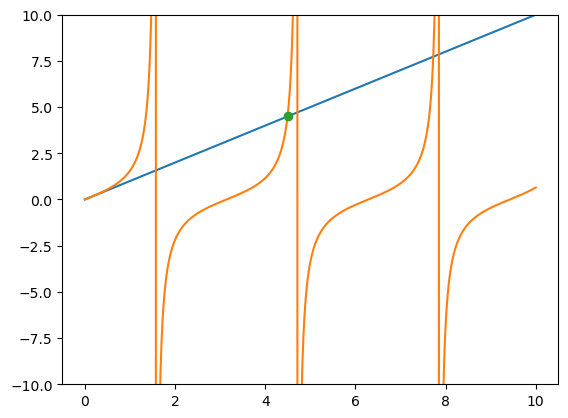

In [31]:
x = np.linspace(0, 10, 2001)
plt.plot(x, x)
plt.plot(x, np.tan(x))
plt.ylim(-10, 10)
plt.plot(res.root, [f(res.root)+res.root], 'o')


### Minimum

- En utilisant la fonction ```minimize_scalar```, calculer le premier minium de la fonction sinus cardinal : 

$$\operatorname{sinc}(x) = \sin(x)/x$$ 

(et lire la documentation de ``np.sinc`` qui ne fait probablement pas ce que vous pensez)

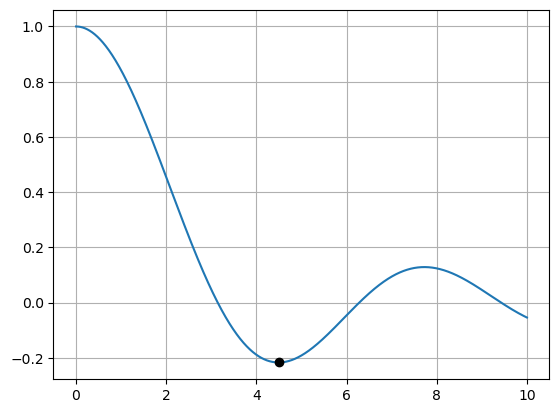

In [35]:
from scipy.optimize import minimize_scalar

def math_sinc(x):
    return np.sinc(x/np.pi)

res = minimize_scalar(math_sinc, [4, 4.71])


plt.plot(x, math_sinc(x))
plt.grid()
plt.plot(res.x, res.fun, 'ko')



### Equation différentielle

La librairie ```scipy.integrate``` contient des fonctions pour résoudre les équations différentielles ordinaires, c'est à dire des équations de la forme :

$$\frac{dy}{dt} = f(t, y)$$
    
avec conditions initiales (on connait $y$ à l'instant $t_0$). La variable $y$ peut être un tableau numpy.

On utilise la fonction ``solve_ivp`` (remplace ``ode`` ou ``odeint``): 

    solve_ivp(fun, t_span, y0, method='RK45', t_eval=None, ...)
    
Il existe plusieurs méthodes d'intégration (par défaut Runge-Kutta d'ordre 5(4) qui adapte la taille des pas)

La fonction ``solve_ivp`` renvoie un objet qui contient le résultat (res.y) mais aussi d'autres informations sur la convergence de l'algorithme.

Exemple : 
$$\frac{dy}{dt} = -y$$    


- Créer la fonction ```f(t, y)```. Cette fonction doit prendre l'argument ```t``` même si celui ci n'est pas utilisé
- Utiliser la ```solve_ivp``` pour résoudre l'équation différentielle. On prendra $y_0=1$ et ```t_span=[0, 4]``` et ```t_eval=np.linspace(0, 4, 110)```. L'argument optionnel ```t_eval``` permet de lui demander des points intemédiaires pour pouvoir tracer l'évolution.
- Tracer la courbe
- Calculer la différence entre la courbe numérique et la courbe théorique. Jouer avec les paramètres ```atol``` et ```rtol``` pour réduire l'écart.

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
# Solve initial value problem

def f(t, y):
    return -y

res = solve_ivp(f, t_span=[0, 4], y0=[1], t_eval=np.linspace(0, 4, 110),
                rtol=1E-9, atol=1E-9)
res

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  3.670e-02 ...  3.963e+00  4.000e+00]
        y: [[ 1.000e+00  9.640e-01 ...  1.900e-02  1.832e-02]]
      sol: None
 t_events: None
 y_events: None
     nfev: 284
     njev: 0
      nlu: 0

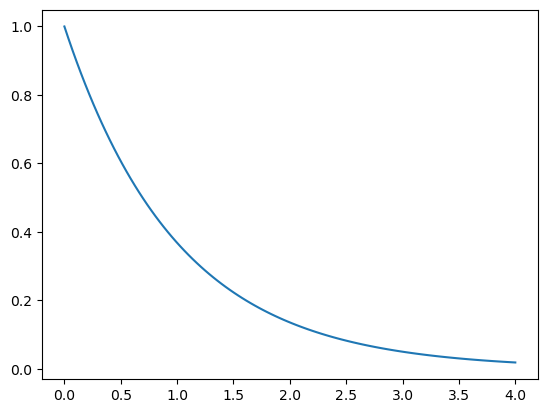

In [11]:
plt.plot(res.t, res.y[0], '-')

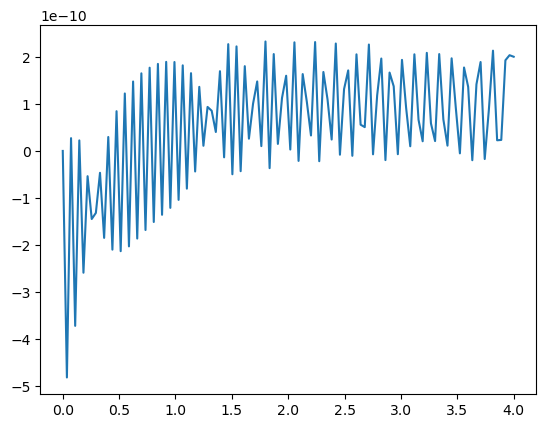

In [12]:
plt.plot(res.t, res.y[0] - np.exp(-res.t), '-')

- Résoudre l'équation $y^\prime = -y/\tau$  en définisant une fonction ```f(t, y, tau)```

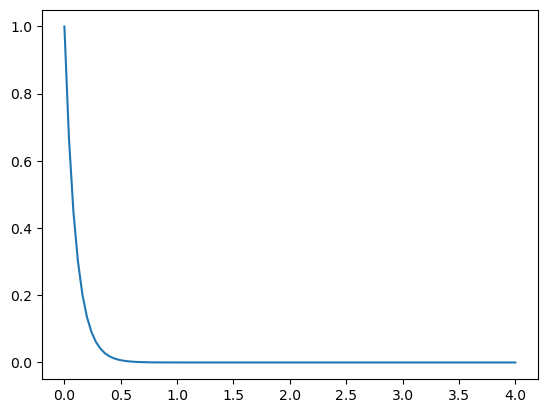

In [39]:
# Utilisation d'un paramètre 
def f(t, y, tau):
    return -y/tau

res = solve_ivp(f, t_span=[0, 4], y0=[1], t_eval=np.linspace(0, 4, 101), args=(0.1,))

plt.plot(res.t, res.y[0], '-')

## Equations différentielles d'ordre élevé

L'astuce consiste à augmenter la dimension de $y$ en rajoutant des fonctions intermédiaires qui sont les dérivées de la fonction initiale.

Par exemple l'équation 

$$\frac{d^2y}{dt^2} = \frac{f(y)}{m}$$

devient 

$$\frac d{dt} \begin{pmatrix}
y \\ 
y ^\prime
\end{pmatrix} = \begin{pmatrix}
y ^\prime \\
f(y)/m
\end{pmatrix} = F(y, y^\prime)$$

Nous allons prendre l'exemple d'une masse sur un ressort. Il est conseillé de bien identifier les variables à l'intérieur de F et de ne pas hésiter à faire des appels à des fonctions dont les arguments ont plus de sens.

Voici ce que cela peut donner :

In [15]:
def force(x, k):
    return -k*x

def F(t, y, k, m):
    position, vitesse = y
    acceleration = force(position, k)/m
    return [vitesse, acceleration]

- Résoudre l'équation différentielle pour $k=1$ et $m=1$.

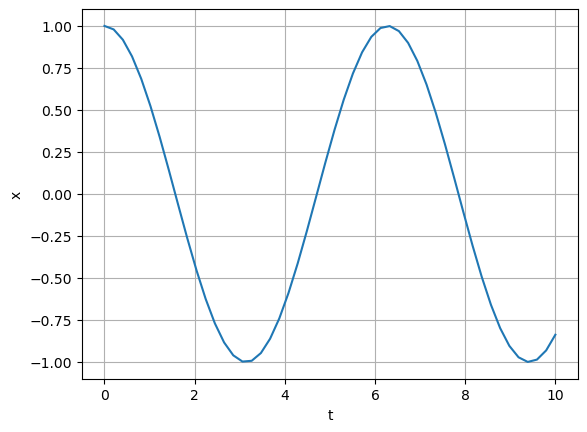

In [40]:
t_eval = np.linspace(0, 10)

res = solve_ivp(F, [0, 10], [1, 0], t_eval=t_eval, args=(1, 1))

plt.plot(res.t, res.y[0])
plt.xlabel('t')
plt.ylabel(r'x')
plt.grid()